SpaCy is one of the top framework (alongside NLTK) for natural language processing. On daily NLP tasks, you cannnot live without it. Here we should explore different concepts such as
- (1) the philosophy of SpaCy
- (2) the concept of pipelines
- (3) creating pipelines
- (4) visiting some interesting case studies.

**How to Install spaCy**

In order to install spaCy, visit their website, here: https://spacy.io/usage

If you are using pip, simply

`!pip install spacy or pip install -U 'spacy[cuda-autodetect]'`

`python -m spacy download en_core_web_sm`

`python -m spacy download en_core_web_md`

For the en_core_web_sm, replace sm with md (medium), lg (large), and trf (transformers). The more complex model you used, the better features you get.

Now that we've installed spaCy let's import it to make sure we installed it correctly.

In [1]:
!pip install spacy

In [9]:
!python -m spacy download en_core_web_sm # small model

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 89.2 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [10]:
!python -m spacy download en_core_web_md # medium model

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.5/33.5 MB 52.9 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [11]:
!python -m spacy download en_core_web_trf  # transformer model

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 457.4/457.4 MB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 237.9/237.9 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 735.6/735.6 kB 20.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 63.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 34.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 35.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

### Data structures
The data structures of spaCy. The overarching container is the Doc, which contains a list of Token where a span of tokens creates a Span(like slicing).

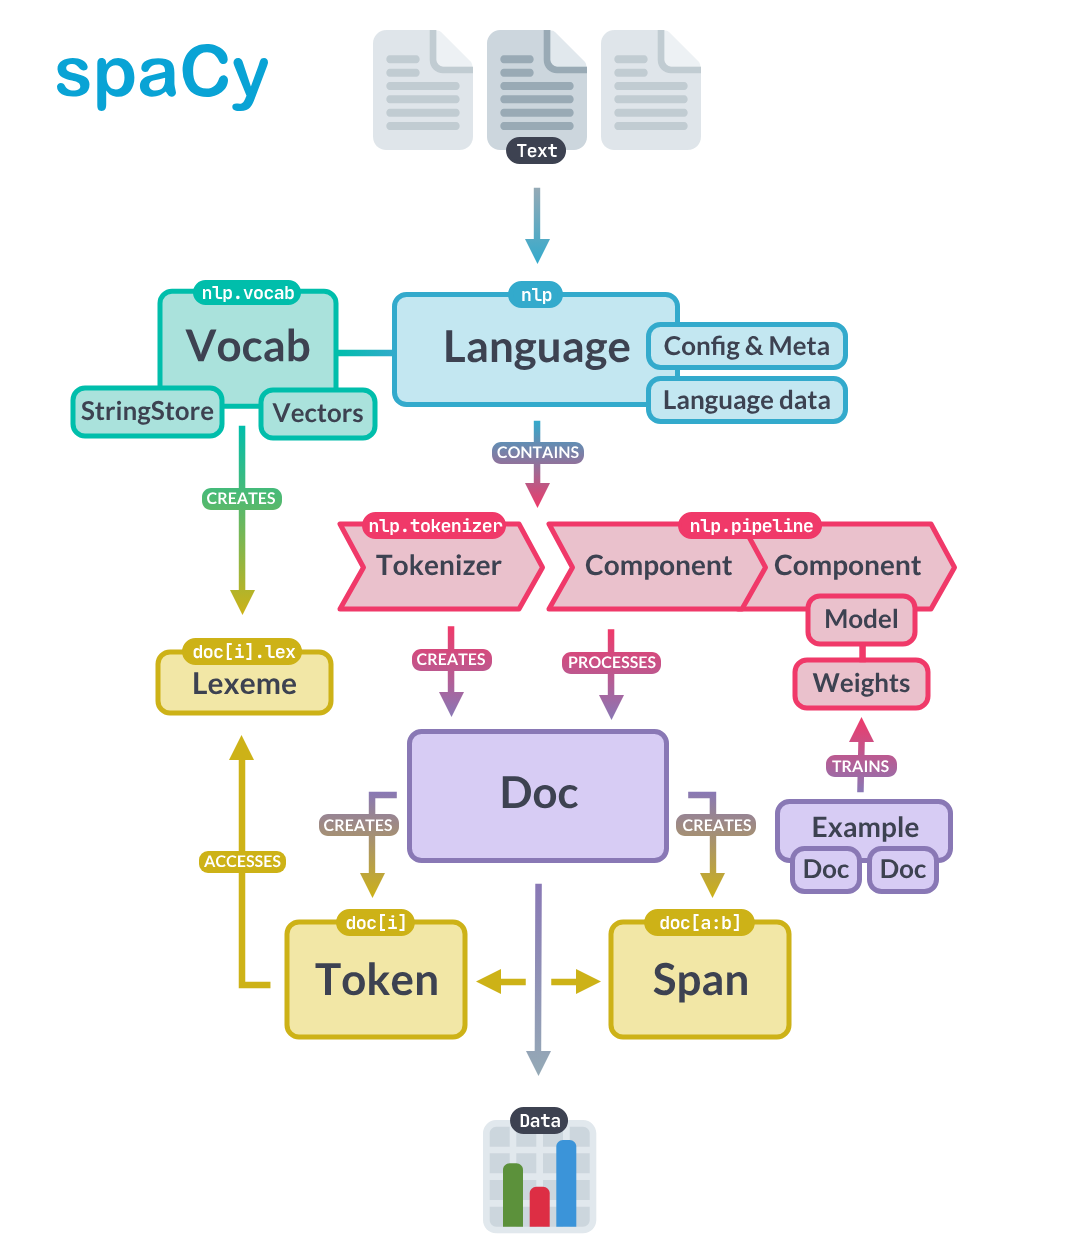

In [ ]:
import spacy

In [ ]:
text = "I am trying out Spacy Library. This is the text I created to wrap around Spacy's basics"

In [ ]:
nlp = spacy.load("en_core_web_md")  # ent only exists from medium model

In [ ]:
doc = nlp(text)
doc

I am trying out Spacy Library. This is the text I created to wrap around Spacy's basics

In [ ]:
for token in doc:
    print(token)

I
am
trying
out
Spacy
Library
.
This
is
the
text
I
created
to
wrap
around
Spacy
's
basics


In [ ]:
for sent in doc.sents:
    print(sent)

I am trying out Spacy Library.
This is the text I created to wrap around Spacy's basics


In [ ]:
doc.ents

(Spacy Library, Spacy)

In [ ]:
for ent in doc.ents:
    print(ent, ent.text, ent.label_)

Spacy Library Spacy Library ORG
Spacy Spacy PRODUCT


In [ ]:
token = doc[-1] # last token

token

basics

In [ ]:
token.lemma_

'basic'

In [ ]:
token.pos_

'NOUN'

In [ ]:
token.dep_

'dobj'

#### **Create Doc object manually**
The Doc is one of the central data structures in spaCy. It's created automatically when you process a text with the nlp object. But you can also instantiate the class manually from `spacy.lang`

After creating the nlp object, we can import the Doc class from `spacy.tokens`.

The Doc class takes three arguments: the shared vocab, the words and the spaces.

In [24]:
# Create an nlp object
from spacy.lang.en import English
nlp = English()

# Import the Doc class
from spacy.tokens import Doc

# The words and spaces to create the doc from
words = ["Hello", "world", "!"]
spaces = [True, False, False]

# Create a doc manually
doc = Doc(vocab=nlp.vocab, words=words, spaces=spaces)

doc

Hello world!

Here we're creating a Doc from three words. The spaces are a list of boolean values indicating whether the word is followed by a space. Every token includes that information – even the last one!


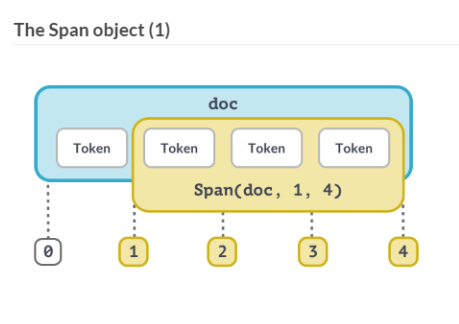

In [26]:
# Create an nlp object
from spacy.lang.en import English
nlp = English()

# Import the Doc and Span class
from spacy.tokens import Doc, Span

# The words and spaces to create the doc from
words = ["Hello", "world", "!"]
spaces = [True, False, False]

# Create a doc manually
doc = Doc(vocab=nlp.vocab, words=words, spaces=spaces)
# Create a span manually
span = Span(doc, start=0, end=2, label="GREETING")

# Add span to the doc.ents
doc.ents = [span]

span  # just 2 tokens

Hello world

In [27]:
doc # we have 3 tokens

Hello world!

#### Creating a Doc Container

With the model loaded, let's go ahead and import our text from Wikipedia.

In [28]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [35]:
!cp -r /content/drive/MyDrive/Colab\ Notebooks/NLP/data/wiki_us.txt .

In [36]:
with open("wiki_us.txt", "r") as f:
    text = f.read()

In [38]:
text

"The United States of America (U.S.A. or USA), commonly known as the United States (U.S. or US) or America, is a country primarily located in North America. It consists of 50 states, a federal district, five major unincorporated territories, 326 Indian reservations, and some minor possessions.[j] At 3.8 million square miles (9.8 million square kilometers), it is the world's third- or fourth-largest country by total area.[d] The United States shares significant land borders with Canada to the north and Mexico to the south, as well as limited maritime borders with the Bahamas, Cuba, and Russia.[22] With a population of more than 331 million people, it is the third most populous country in the world. The national capital is Washington, D.C., and the most populous city is New York."

In [40]:
nlp = spacy.load("en_core_web_sm")
nlp

In [41]:
doc = nlp(text)
doc

The United States of America (U.S.A. or USA), commonly known as the United States (U.S. or US) or America, is a country primarily located in North America. It consists of 50 states, a federal district, five major unincorporated territories, 326 Indian reservations, and some minor possessions.[j] At 3.8 million square miles (9.8 million square kilometers), it is the world's third- or fourth-largest country by total area.[d] The United States shares significant land borders with Canada to the north and Mexico to the south, as well as limited maritime borders with the Bahamas, Cuba, and Russia.[22] With a population of more than 331 million people, it is the third most populous country in the world. The national capital is Washington, D.C., and the most populous city is New York.

**so what's the difference between raw text and doc?**

In [42]:
print(len(doc), len(text))

156 787


Same text, but different length. Why does this occur? To answer that, let's explore it more deeply and try and print off each item in each object.

In [43]:
for token in text[:10]:
    print(token)

T
h
e
 
U
n
i
t
e
d


In [44]:
for token in doc[:10]:
    print(token)

The
United
States
of
America
(
U.S.A.
or
USA
)


And now we see the magical difference. Tokens are created through the `en_core_web_sm`. Another difference is the concept of sents which refer to sentences.

In [45]:
for sent in doc.sents:
    print(sent)

The United States of America (U.S.A. or USA), commonly known as the United States (U.S. or US) or America, is a country primarily located in North America.
It consists of 50 states, a federal district, five major unincorporated territories, 326 Indian reservations, and some minor possessions.[j]
At 3.8 million square miles (9.8 million square kilometers), it is the world's third- or fourth-largest country by total area.[d]
The United States shares significant land borders with Canada to the north and Mexico to the south, as well as limited maritime borders with the Bahamas, Cuba, and Russia.[22] With a population of more than 331 million people, it is the third most populous country in the world.
The national capital is Washington, D.C., and the most populous city is New York.


In [46]:
sentence1 = list(doc.sents)[0]
sentence1

The United States of America (U.S.A. or USA), commonly known as the United States (U.S. or US) or America, is a country primarily located in North America.

We can explore deeper into token attributes which hides many crazy good stuff.

In [47]:
token2 = sentence1[2]
token2

States

In [48]:
token2.text  # raw text

'States'

In [49]:
token2.head  # head of the dependency tree

is

In [50]:
token2.left_edge # this tell us where the multi-word token begins

The

In [51]:
token2.right_edge # this tell us where the multi-word token ends

,

In [52]:
token2.ent_type  # type of entity - i.e number for entity type

384

In [54]:
token2.ent_type_  # the actual name of the entity - Geo political entities

'GPE'

In [55]:
spacy.explain("GPE")  # view the entity info

'Countries, cities, states'

In [56]:
token2.is_sent_end # check if it is sentence end token

False

In [67]:
token2.is_alpha, token2.is_currency, token2.is_digit, token2.is_lower, token2.is_punct, token2.is_oov, token2.is_quote, token2.is_sent_start, token2.is_bracket, token2.is_title, token2.is_title, token2.is_stop, token2.is_ascii

(True,
 False,
 False,
 False,
 False,
 True,
 False,
 False,
 False,
 True,
 True,
 False,
 True)

In [87]:
token2.like_email, token2.like_num, token.like_url

(False, False, False)

In [73]:
token2.ent_iob_  # “B” means the token begins an entity, “I” means it is inside an entity, “O” means it is outside an entity, and "" means no entity tag is set.

'I'

In [82]:
token2.lang_

'en'

In [74]:
token2.lemma_  # the root form of the word

'States'

In [76]:
sentence1[12], sentence1[12].lemma_

(known, 'know')

In [77]:
sentence1[12].lemma # without _, it will give you an hash integer representation instead

7743033266031195906

In [79]:
token2.pos_ # pos

'PROPN'

In [80]:
token2.dep_ # Syntactic Dependency

'nsubj'

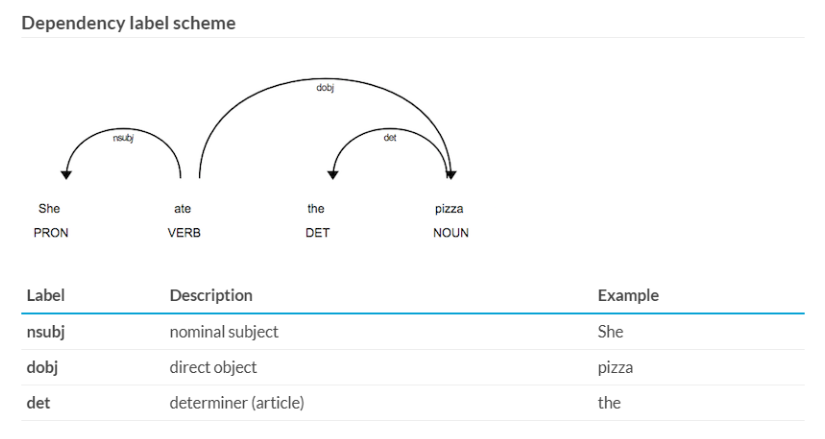

In [81]:
spacy.explain("nsubj")

'nominal subject'

In [86]:
from spacy import displacy

displacy.render(sentence1, style="dep")

**Part of Speech Tagging (POS)**

In the field of computational linguistics, understanding parts-of-speech is essential. SpaCy offers an easy way to parse a text and identify its parts of speech. Below, we will iterate across each token (word or punctuation) in the text and identify its part of speech.

In [92]:
doc = nlp("Peter loves eating and Paris very much.")
sentence1 = list(doc.sents)[0]
sentence1

Peter loves eating and Paris very much.

In [93]:
for token in sentence1:
    print(token.text, token.pos_, token.dep_)

Peter PROPN nsubj
loves VERB ROOT
eating VERB xcomp
and CCONJ cc
Paris PROPN conj
very ADV advmod
much ADV advmod
. PUNCT punct


Here, we can see two vital pieces of information: the string and the corresponding part-of-speech (pos).

For a complete list of the pos labels, see the spaCy documentation (https://spacy.io/api/annotation#pos-tagging). Most of these, however, should be apparent, i.e. PROPN is proper noun, AUX is an auxiliary verb, ADJ, is adjective, etc. We can visualize this sentence with a diagram through spaCy's displaCy Notebook feature.

In [94]:
from spacy import displacy
displacy.render(sentence1, style="dep")

In [109]:
import spacy

nlp = spacy.load("en_core_web_sm")
doc = nlp("Berlin is a nice city and I like to Paris hopping")

for token in doc:
    if token.pos_ == "PROPN":
        if doc[token.i + 1].pos_ == "VERB":
            print("Found proper noun before a verb:", token.text)

Found proper noun before a verb: Paris


In [110]:
for token in doc:
    print(token.i, token.text, token.pos_)

0 Berlin PROPN
1 is AUX
2 a DET
3 nice ADJ
4 city NOUN
5 and CCONJ
6 I PRON
7 like VERB
8 to ADP
9 Paris PROPN
10 hopping VERB


Another essential task of NLP, is named entity recognition, or NER. SpaCy provides doc.ents.

In [111]:
for ent in doc.ents:
    print(ent.text, ent.label_)

Berlin GPE
Paris GPE


We can use displaCy to display the text as NER annotations

In [113]:
from spacy import displacy

import spacy

nlp = spacy.load("en_core_web_sm")
doc = nlp("Berlin is a nice city and I like to Paris hopping")

displacy.render(doc, style="ent")

In [114]:
from spacy import displacy

import spacy

nlp = spacy.load("en_core_web_sm")
doc = nlp("Peter loves eating and Paris very much.")

displacy.render(list(doc.sents)[0], style="ent")

#### Word Vectors

Let's explore word vectors a bit.

To do so, we shall use `en_core_web_md` which contains word vectors.

In [115]:
import spacy

nlp = spacy.load("en_core_web_md")

with open ("wiki_us.txt", "r") as f:
    text = f.read()

doc = nlp(text)
sentence1 = list(doc.sents)[0]

In [116]:
sentence1

The United States of America (U.S.A. or USA), commonly known as the United States (U.S. or US) or America, is a country primarily located in North America.

In [118]:
token1 = sentence1[0]
token1

The

In [119]:
token1.vector.shape  # 300 dimensions representing "The"

(300,)

In [120]:
token1.vector[:5]

array([-0.65276,  0.23873, -0.23325,  0.18608,  0.37674], dtype=float32)

#### Similarity

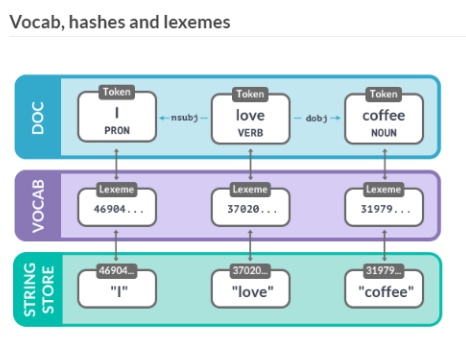

In [123]:
#before similarity, let's see about nlp.vocab.strings
import spacy

nlp = spacy.load("en_core_web_md")
doc = nlp("I love coffee")

print('hash value:', nlp.vocab.strings['coffee'])  # hash value

hash value: 3197928453018144401


In [124]:
print('string value:', nlp.vocab.strings[3197928453018144401])

string value: coffee


In [125]:
# 1st numercalize
doghash = nlp.vocab.strings["dog"]
doghash

7562983679033046312

In [126]:
# 2nd get the vector
dogvector = nlp.vocab.vectors[doghash]
dogvector.shape

(300,)

In [127]:
dogvector[:10]

array([-0.72483 ,  0.42538 ,  0.025489, -0.39807 ,  0.037463, -0.29811 ,
       -0.28279 ,  0.29333 ,  0.57775 ,  1.2205  ], dtype=float32)

In [128]:
# similarity
import numpy as np


# obtain words that are most similar to this vector, need to put [] because most_similar accept numpy array of vectors
similar_words = nlp.vocab.vectors.most_similar(np.asarray([dogvector]), n=10)

similar_words  # vocab has id, token id in vocab, similarity score

(array([[15620824655973016153, 14199852958745354380,  9812465697972488375,
         16404495417672189842,  9120157979859245900, 18396330015683239431,
         17686863692678987895, 17013543403266394153,  6778916106837546498,
         15155727695527527307]], dtype=uint64),
 array([[9979, 9980, 9981, 4793, 4791, 4792, 7918, 7917, 7916,  451]],
       dtype=int32),
 array([[1.    , 1.    , 1.    , 0.7044, 0.7044, 0.7044, 0.6588, 0.6588,
         0.6588, 0.6366]], dtype=float32))

In [129]:
similar_words[0].shape

(1, 10)

In [130]:
similar_words[0]

array([[15620824655973016153, 14199852958745354380,  9812465697972488375,
        16404495417672189842,  9120157979859245900, 18396330015683239431,
        17686863692678987895, 17013543403266394153,  6778916106837546498,
        15155727695527527307]], dtype=uint64)

In [135]:
similar_words = similar_words[0].reshape(-1)

In [136]:
similar_words.shape

(10,)

In [137]:
similar_words

array([15620824655973016153, 14199852958745354380,  9812465697972488375,
       16404495417672189842,  9120157979859245900, 18396330015683239431,
       17686863692678987895, 17013543403266394153,  6778916106837546498,
       15155727695527527307], dtype=uint64)

In [139]:
for wordhash in similar_words:
    print(nlp.vocab.strings[wordhash])

pooch
CHINCHILLA
CORGI
adopt
cattery
ADOPTED
CHINCHILLAS
goldendoodles
cockapoos
sighthound


#### Doc Similarity
In spaCy we can do this same thing at the document level.

In [141]:
doc1 = nlp("I like salty fries and hamburgers.")
doc2 = nlp("Fast food tastes very good.")

# Similarity of two documents
print(doc1, "<->", doc2, doc1.similarity(doc2))

I like salty fries and hamburgers. <-> Fast food tastes very good. 0.8015960454940796


#### Word Similarity
We can also calculate the similarity between two given words.

In [142]:
# Similarity of tokens and spans
french_fries = doc1[2:4]  # span
burgers = doc1[5]  # token

print(french_fries, "<->", burgers, french_fries.similarity(burgers))

salty fries <-> hamburgers 0.5733411312103271


#### Span Similarity

In [143]:
import spacy

doc = nlp("This was a great restaurant. Afterwards, we went to a really nice bar.")

# Create spans for "great restaurant" and "really nice bar"
span1 = doc[3:5]
span2 = doc[12:15]

# Get the similarity of the spans
similarity = span1.similarity(span2)
print(similarity)

0.7541285157203674


### Spacy Pipelines

As we have seen, spaCy automatically tokenize, sentenize, and automatically gives us POS, entities, etc. Behind the magic is performed by some existing pipes trained in `en_core_web_X`. A pipeline is a sequence of pipes, that transforms or extracts our data.

What's good is that we can add and train these pipes ourselves to fit our needs!

Let's first examine the pipe in en_core_web_sm, then we shall create our own.

In [145]:
import spacy

nlp = spacy.load("en_core_web_sm")

# Note that these pipes execute sequentially....
analysis = nlp.analyze_pipes(pretty=True)   # print the existing pipeline


============================= Pipeline Overview =============================

#   Component         Assigns               Requires   Scores             Retokenizes
-   ---------------   -------------------   --------   ----------------   -----------
0   tok2vec           doc.tensor                                          False      
                                                                                     
1   tagger            token.tag                        tag_acc            False      
                                                                                     
2   parser            token.dep                        dep_uas            False      
                      token.head                       dep_las                       
                      token.is_sent_start              dep_las_per_type              
                      doc.sents                        sents_p                       
                                                       sents

In [146]:
analysis

{'summary': {'tok2vec': {'assigns': ['doc.tensor'],
   'requires': [],
   'scores': [],
   'retokenizes': False},
  'tagger': {'assigns': ['token.tag'],
   'requires': [],
   'scores': ['tag_acc'],
   'retokenizes': False},
  'parser': {'assigns': ['token.dep',
    'token.head',
    'token.is_sent_start',
    'doc.sents'],
   'requires': [],
   'scores': ['dep_uas',
    'dep_las',
    'dep_las_per_type',
    'sents_p',
    'sents_r',
    'sents_f'],
   'retokenizes': False},
  'attribute_ruler': {'assigns': [],
   'requires': [],
   'scores': [],
   'retokenizes': False},
  'lemmatizer': {'assigns': ['token.lemma'],
   'requires': [],
   'scores': ['lemma_acc'],
   'retokenizes': False},
  'ner': {'assigns': ['doc.ents', 'token.ent_iob', 'token.ent_type'],
   'requires': [],
   'scores': ['ents_f', 'ents_p', 'ents_r', 'ents_per_type'],
   'retokenizes': False}},
 'problems': {'tok2vec': [],
  'tagger': [],
  'parser': [],
  'attribute_ruler': [],
  'lemmatizer': [],
  'ner': []},
 'att

#### 1. How to add pre-built Pipes

In real world, we will probably use an off-the-shelf spaCy model. In some cases, however, an off-the-shelf model will not fill your needs or will perform a specific task very slowly. Sometimes you want a smaller model, not having so many pipes (e.g., just senticizer), thus faster...

To demonstrate this process, let's first create a blank model.

In [151]:
import spacy

nlp = spacy.blank("en")
nlp

In [152]:
nlp.analyze_pipes(pretty=True)


============================= Pipeline Overview =============================

#   Component   Assigns   Requires   Scores   Retokenizes
-   ---------   -------   --------   ------   -----------

✔ No problems found.


{'summary': {}, 'problems': {}, 'attrs': {}}

In [153]:
nlp.add_pipe("sentencizer")

In [154]:
nlp.analyze_pipes(pretty=True)


============================= Pipeline Overview =============================

#   Component     Assigns               Requires   Scores    Retokenizes
-   -----------   -------------------   --------   -------   -----------
0   sentencizer   token.is_sent_start              sents_f   False      
                  doc.sents                        sents_p              
                                                   sents_r              

✔ No problems found.


{'summary': {'sentencizer': {'assigns': ['token.is_sent_start', 'doc.sents'],
   'requires': [],
   'scores': ['sents_f', 'sents_p', 'sents_r'],
   'retokenizes': False}},
 'problems': {'sentencizer': []},
 'attrs': {'doc.sents': {'assigns': ['sentencizer'], 'requires': []},
  'token.is_sent_start': {'assigns': ['sentencizer'], 'requires': []}}}

In [156]:
with open ("wiki_us.txt", "r") as f:
    text = f.read()

text

"The United States of America (U.S.A. or USA), commonly known as the United States (U.S. or US) or America, is a country primarily located in North America. It consists of 50 states, a federal district, five major unincorporated territories, 326 Indian reservations, and some minor possessions.[j] At 3.8 million square miles (9.8 million square kilometers), it is the world's third- or fourth-largest country by total area.[d] The United States shares significant land borders with Canada to the north and Mexico to the south, as well as limited maritime borders with the Bahamas, Cuba, and Russia.[22] With a population of more than 331 million people, it is the third most populous country in the world. The national capital is Washington, D.C., and the most populous city is New York."

In [158]:
%%time
doc = nlp(text)
print(len(list(doc.sents)))

3
CPU times: user 737 µs, sys: 0 ns, total: 737 µs
Wall time: 744 µs


In [159]:
nlp2 = spacy.load("en_core_web_sm")
nlp2.max_length = 5278439

In [160]:
%%time
doc = nlp2(text)
print (len(list(doc.sents)))

5
CPU times: user 77.1 ms, sys: 3.8 ms, total: 80.9 ms
Wall time: 93.8 ms


The difference in time here is remarkable! Thus, sometimes, it may be good to start a blank model and add the pre-built pipe.....

#### 2. EntityRuler
The Python library spaCy offers a few different methods for performing `rules-based NER`. One such method is via its `EntityRuler`.

The EntityRuler is a spaCy factory that allows one to create a set of patterns with corresponding labels.

We will be looking closely at the EntityRuler as a component of a spaCy model's pipeline. Off-the-shelf spaCy models come preloaded with an NER model; they do not, however, come with an EntityRuler. In order to incorperate an EntityRuler into a spaCy model, it must be created as a new pipe, given instructions, and then added to the model. Once this is complete, the user can save that new model with the EntityRuler to the disk.

The full documentation of spaCy EntityRuler can be found here: https://spacy.io/api/entityruler

In [161]:
import spacy
nlp = spacy.load("en_core_web_sm")

nlp.analyze_pipes(pretty=True)

#sample text
text = "Asian Institute of Technology, founded in 1959, situated 40km north of Bangkok, Thailand, near Rangsit ."

#Create the Doc object
doc = nlp(text)

#extract entities
for ent in doc.ents:
    print (ent.text, ent.label_)


============================= Pipeline Overview =============================

#   Component         Assigns               Requires   Scores             Retokenizes
-   ---------------   -------------------   --------   ----------------   -----------
0   tok2vec           doc.tensor                                          False      
                                                                                     
1   tagger            token.tag                        tag_acc            False      
                                                                                     
2   parser            token.dep                        dep_uas            False      
                      token.head                       dep_las                       
                      token.is_sent_start              dep_las_per_type              
                      doc.sents                        sents_p                       
                                                       sents

Here, let's try to teach the model that Rangsit is a LOC instead, not GPE.

In [163]:
import spacy

#Build upon the spaCy Small Model
nlp = spacy.load("en_core_web_sm")

# Create the EntityRuler, a rule-based entity extraction (i.e., no machine learning involved....)
ruler = nlp.add_pipe("entity_ruler")

# List of Entities and Patterns
patterns = [
    {
        "label": "LOC",
        "pattern": "Rangsit"
    }
] # list of dicts

ruler.add_patterns(patterns)

nlp.analyze_pipes(pretty=True)

print(nlp.pipe_names)

text = "Asian Institute of Technology, founded in 1959, situated 40km north of Bangkok, Thailand, near Rangsit ."
doc = nlp(text)

for ent in doc.ents:
    print(ent.text, ent.label_)


============================= Pipeline Overview =============================

#   Component         Assigns               Requires   Scores             Retokenizes
-   ---------------   -------------------   --------   ----------------   -----------
0   tok2vec           doc.tensor                                          False      
                                                                                     
1   tagger            token.tag                        tag_acc            False      
                                                                                     
2   parser            token.dep                        dep_uas            False      
                      token.head                       dep_las                       
                      token.is_sent_start              dep_las_per_type              
                      doc.sents                        sents_p                       
                                                       sents

This method has failed. Why? The answer comes back to the concept of pipelines. We created and added the EntityRuler to the spaCy model's pipeline, but by default, spaCy add's a new pipe to the end of the pipeline. Observe the visualized pipeline.

This can be a bit difficult to read at first, but what it shows us is the order in which our pipes are set up and a few other key pieces of information about each pipe. If we locate "ner", we notice that "entity_ruler" sits behind it.

In order for our EntityRuler to have primacy, we have to assign it to before the "ner" pipe.

In [164]:
import spacy

#Build upon the spaCy Small Model
nlp = spacy.load("en_core_web_sm")

# Create the EntityRuler, a rule-based entity extraction (i.e., no machine learning involved....)
ruler = nlp.add_pipe("entity_ruler", before="ner")

# List of Entities and Patterns
patterns = [
    {
        "label": "LOC",
        "pattern": "Rangsit"
    }
] # list of dict

ruler.add_patterns(patterns)

nlp.analyze_pipes(pretty=True)

text = "Asian Institute of Technology, founded in 1959, situated 40km north of Bangkok, Thailand, near Rangsit ."
doc = nlp(text)

for ent in doc.ents:
    print(ent.text, ent.label_)


============================= Pipeline Overview =============================

#   Component         Assigns               Requires   Scores             Retokenizes
-   ---------------   -------------------   --------   ----------------   -----------
0   tok2vec           doc.tensor                                          False      
                                                                                     
1   tagger            token.tag                        tag_acc            False      
                                                                                     
2   parser            token.dep                        dep_uas            False      
                      token.head                       dep_las                       
                      token.is_sent_start              dep_las_per_type              
                      doc.sents                        sents_p                       
                                                       sents

Nice! What we learn is that once the label is assigned, it won't change anymore...

#### EntityRuler (Advanced)
The spaCy EntityRuler also allows the user to introduce a variety of complex rules and variances (via, among other things, RegEx) by passing the rules to the pattern. For a complete list, see: https://spacy.io/usage/rule-based-matching

In [166]:
import spacy

#Sample text
text = "This is a sample number (555) 555-5555."

nlp = spacy.blank("en")

ruler = nlp.add_pipe("entity_ruler")

patterns = [
    {
        "label": "PHONE_NUMBER",
        "pattern": [
            {"ORTH": "("},
            {"SHAPE": "ddd"},
            {"ORTH": ")"},
            {"SHAPE": "ddd"},
            {"ORTH": "-", "OP": "?"},  # accepts 0 or 1 occurence of "-"
            {"SHAPE": "dddd"},
        ] # list[dicts], ORTH - exact string match, shape: checks the pattern, OP: tells about the occurence where ? is 1 or 0, + is 1 or more
    }
]  # list[dict]

ruler.add_patterns(patterns)

doc = nlp(text)

# extract entities
for ent in doc.ents:
    print (ent.text, ent.label_)

(555) 555-5555 PHONE_NUMBER


#### Matcher

Let's use Matcher to further allow us to extract information.

In [167]:
from spacy.matcher import Matcher

In [168]:
nlp = spacy.load("en_core_web_sm")
matcher = Matcher(vocab=nlp.vocab)

pattern = [{"LIKE_EMAIL": True}]  # pre-defined keys
matcher.add(key="EMAIL_ADDRESS", patterns=[pattern]) # key is user-defined here

doc = nlp("This is an email address: wmattingly@aol.com")

matches = matcher(doc)
matches  # lexeme, start token

[(16571425990740197027, 6, 7)]

In [169]:
nlp.vocab.strings[matches[0][0]]

'EMAIL_ADDRESS'

In [171]:
print(nlp.vocab[matches[0][0]].text)

EMAIL_ADDRESS


In [170]:
doc[6:7]

wmattingly@aol.com

In [174]:
!cp -r /content/drive/MyDrive/Colab\ Notebooks/NLP/data/wiki_king.txt .

In [175]:
# Proper nouns with matcher
with open ("wiki_king.txt", "r") as f:
    text = f.read()
print(text)

nlp = spacy.load("en_core_web_sm")
matcher = Matcher(nlp.vocab)

pattern = [{"POS": "PROPN"}]
matcher.add(key="PROPER_NOUNS", patterns=[pattern])

doc = nlp(text)

matches = matcher(doc)
print(len(matches))

for match in matches[:10]:
    print(match, doc[match[1]:match[2]])

Martin Luther King Jr. (born Michael King Jr.; January 15, 1929 – April 4, 1968) was an American Baptist minister and activist who became the most visible spokesman and leader in the American civil rights movement from 1955 until his assassination in 1968. King advanced civil rights through nonviolence and civil disobedience, inspired by his Christian beliefs and the nonviolent activism of Mahatma Gandhi. He was the son of early civil rights activist and minister Martin Luther King Sr.

King participated in and led marches for blacks' right to vote, desegregation, labor rights, and other basic civil rights.[1] King led the 1955 Montgomery bus boycott and later became the first president of the Southern Christian Leadership Conference (SCLC). As president of the SCLC, he led the unsuccessful Albany Movement in Albany, Georgia, and helped organize some of the nonviolent 1963 protests in Birmingham, Alabama. King helped organize the 1963 March on Washington, where he delivered his famous 

In [176]:
# Improving the matching tokens with Multi-Word Tokens

# Proper nouns with matcher
with open ("wiki_king.txt", "r") as f:
    text = f.read()
print(text)

nlp = spacy.load("en_core_web_sm")
matcher = Matcher(nlp.vocab)

pattern = [{"POS": "PROPN", "OP": "+"}] # one or more tokens
matcher.add(key="PROPER_NOUNS", patterns=[pattern])

doc = nlp(text)

matches = matcher(doc)
print(len(matches))

for match in matches[:10]:
    print(match, doc[match[1]:match[2]])

Martin Luther King Jr. (born Michael King Jr.; January 15, 1929 – April 4, 1968) was an American Baptist minister and activist who became the most visible spokesman and leader in the American civil rights movement from 1955 until his assassination in 1968. King advanced civil rights through nonviolence and civil disobedience, inspired by his Christian beliefs and the nonviolent activism of Mahatma Gandhi. He was the son of early civil rights activist and minister Martin Luther King Sr.

King participated in and led marches for blacks' right to vote, desegregation, labor rights, and other basic civil rights.[1] King led the 1955 Montgomery bus boycott and later became the first president of the Southern Christian Leadership Conference (SCLC). As president of the SCLC, he led the unsuccessful Albany Movement in Albany, Georgia, and helped organize some of the nonviolent 1963 protests in Birmingham, Alabama. King helped organize the 1963 March on Washington, where he delivered his famous 

"OP" can have one of four values:

An "!" negates the token, so it's matched 0 times.

A "?" makes the token optional, and matches it 0 or 1 times.

A "+" matches a token 1 or more times.

And finally, an "*" matches 0 or more times.

Operators can make your patterns a lot more powerful, but they also add more complexity – so use them wisely.

{'OP': '!'} Negation: match 0 times

{'OP': '?'} Optional: match 0 or 1 times

{'OP': '+'} Match 1 or more times

{'OP': '*'} Match 0 or more times

In [177]:
# Greedy Keyword Argument

# Improving the matching tokens with Multi-Word Tokens

# Proper nouns with matcher
with open ("wiki_king.txt", "r") as f:
    text = f.read()
print(text)

nlp = spacy.load("en_core_web_sm")
matcher = Matcher(nlp.vocab)

pattern = [{"POS": "PROPN", "OP": "+"}] # one or more tokens
matcher.add(key="PROPER_NOUNS", patterns=[pattern], greedy="LONGEST")

doc = nlp(text)

matches = matcher(doc)
print(len(matches))

for match in matches[:10]:
    print(match, doc[match[1]:match[2]])

Martin Luther King Jr. (born Michael King Jr.; January 15, 1929 – April 4, 1968) was an American Baptist minister and activist who became the most visible spokesman and leader in the American civil rights movement from 1955 until his assassination in 1968. King advanced civil rights through nonviolence and civil disobedience, inspired by his Christian beliefs and the nonviolent activism of Mahatma Gandhi. He was the son of early civil rights activist and minister Martin Luther King Sr.

King participated in and led marches for blacks' right to vote, desegregation, labor rights, and other basic civil rights.[1] King led the 1955 Montgomery bus boycott and later became the first president of the Southern Christian Leadership Conference (SCLC). As president of the SCLC, he led the unsuccessful Albany Movement in Albany, Georgia, and helped organize some of the nonviolent 1963 protests in Birmingham, Alabama. King helped organize the 1963 March on Washington, where he delivered his famous 

In [179]:
# sorting the greedy longest matches
with open ("wiki_king.txt", "r") as f:
    text = f.read()
print(text)

nlp = spacy.load("en_core_web_sm")
matcher = Matcher(nlp.vocab)

pattern = [{"POS": "PROPN", "OP": "+"}] # one or more tokens
matcher.add(key="PROPER_NOUNS", patterns=[pattern], greedy="LONGEST")

doc = nlp(text)

matches = matcher(doc)
print(len(matches))

matches.sort(key=lambda x: x[1])  # sort the matches by their occurence in the text. i.e first index of sliced match

for match in matches[:10]:
    print(match, doc[match[1]:match[2]])

Martin Luther King Jr. (born Michael King Jr.; January 15, 1929 – April 4, 1968) was an American Baptist minister and activist who became the most visible spokesman and leader in the American civil rights movement from 1955 until his assassination in 1968. King advanced civil rights through nonviolence and civil disobedience, inspired by his Christian beliefs and the nonviolent activism of Mahatma Gandhi. He was the son of early civil rights activist and minister Martin Luther King Sr.

King participated in and led marches for blacks' right to vote, desegregation, labor rights, and other basic civil rights.[1] King led the 1955 Montgomery bus boycott and later became the first president of the Southern Christian Leadership Conference (SCLC). As president of the SCLC, he led the unsuccessful Albany Movement in Albany, Georgia, and helped organize some of the nonviolent 1963 protests in Birmingham, Alabama. King helped organize the 1963 March on Washington, where he delivered his famous 

In [180]:
# Adding in Sequences of match patterns

with open ("wiki_king.txt", "r") as f:
    text = f.read()
print(text)

nlp = spacy.load("en_core_web_sm")
matcher = Matcher(nlp.vocab)

pattern = [{"POS": "PROPN", "OP": "+"}, {"POS": "VERB"}] # PROPN followed by verb
matcher.add(key="PROPER_NOUNS", patterns=[pattern], greedy="LONGEST")

doc = nlp(text)

matches = matcher(doc)
print(len(matches))

matches.sort(key=lambda x: x[1])  # sort the matches by their occurence in the text. i.e first index of sliced match

for match in matches[:10]:
    print(match, doc[match[1]:match[2]])

Martin Luther King Jr. (born Michael King Jr.; January 15, 1929 – April 4, 1968) was an American Baptist minister and activist who became the most visible spokesman and leader in the American civil rights movement from 1955 until his assassination in 1968. King advanced civil rights through nonviolence and civil disobedience, inspired by his Christian beliefs and the nonviolent activism of Mahatma Gandhi. He was the son of early civil rights activist and minister Martin Luther King Sr.

King participated in and led marches for blacks' right to vote, desegregation, labor rights, and other basic civil rights.[1] King led the 1955 Montgomery bus boycott and later became the first president of the Southern Christian Leadership Conference (SCLC). As president of the SCLC, he led the unsuccessful Albany Movement in Albany, Georgia, and helped organize some of the nonviolent 1963 protests in Birmingham, Alabama. King helped organize the 1963 March on Washington, where he delivered his famous 

In [181]:
### Use built-in match patterns
nlp = spacy.load("en_core_web_sm")
doc = nlp("2018 FIFA World Cup: France won!")

# Initialize the matcher with the shared vocab
matcher = Matcher(nlp.vocab)

pattern = [
    {"IS_DIGIT": True},
    {"LOWER": "fifa"},
    {"LOWER": "world"},
    {"LOWER": "cup"},
    {"IS_PUNCT": True}
]

# Add the pattern to the matcher
matcher.add('FIFA', [pattern])

# Process some text

# Call the matcher on the doc
matches = matcher(doc)

for match, start, end in matches:
    matched_span = doc[start:end]
    print(matched_span.text)

2018 FIFA World Cup:


In [183]:
nlp = spacy.load("en_core_web_sm")
doc = nlp("I loved dogs but now I love cats more.")

# Initialize the matcher with the shared vocab
matcher = Matcher(nlp.vocab)

pattern = [{"LEMMA": "love", "POS": "VERB"},
           {"POS": "NOUN"}]
# Add the pattern to the matcher
matcher.add("PETS", [pattern])

# Process some text

# Call the matcher on the doc
matches = matcher(doc)

# Iterate over the matches
for match_id, start, end in matches:
    # Get the matched span
    matched_span = doc[start:end]
    print(matched_span.text)

loved dogs
love cats


In [184]:
nlp = spacy.load("en_core_web_sm")
doc = nlp("I bought a smartphone. Now I'm buying apps.")

# Initialize the matcher with the shared vocab
matcher = Matcher(nlp.vocab)

pattern = [
    {"LEMMA": "buy"},
    {"POS": "DET", "OP": "?"},  # match 0 or 1 times
    {"POS": "NOUN"}
]
# Add the pattern to the matcher
matcher.add('CONSUME', [pattern])

# Process some text

# Call the matcher on the doc
matches = matcher(doc)

# Iterate over the matches
for match_id, start, end in matches:
    # Get the matched span
    matched_span = doc[start:end]
    print(matched_span.text)

bought a smartphone
buying apps


In [185]:
nlp = spacy.load("en_core_web_sm")
matcher = Matcher(nlp.vocab)

doc = nlp(
    "i downloaded Fortnite on my laptop and can't open the game at all. Help? "
    "so when I was downloading Minecraft, I got the Windows version where it "
    "is the '.zip' folder and I used the default program to unpack it... do "
    "I also need to download Winzip?"
)

# Write a pattern that matches a form of "download" plus proper noun
pattern = [{"LEMMA": 'download'}, {"POS": 'PROPN'}]

# Add the pattern to the matcher and apply the matcher to the doc
matcher.add("DOWNLOAD_THINGS_PATTERN", [pattern])
matches = matcher(doc)
print("Total matches found:", len(matches))

# Iterate over the matches and print the span text
for match_id, start, end in matches:
    print("Match found:", doc[start:end].text)

Total matches found: 3
Match found: downloaded Fortnite
Match found: downloading Minecraft
Match found: download Winzip


In [186]:
nlp = spacy.load("en_core_web_sm")
matcher = Matcher(nlp.vocab)

doc = nlp(
    "Features of the app include a beautiful design, smart search, automatic "
    "labels and optional voice responses."
)

# Write a pattern for adjective plus one or two nouns
pattern = [{"POS": "ADJ"}, {"POS": "NOUN"}, {"POS": "NOUN", "OP": "?"}]

# Add the pattern to the matcher and apply the matcher to the doc
matcher.add("ADJ_NOUN_PATTERN", [pattern])
matches = matcher(doc)
print("Total matches found:", len(matches))

# Iterate over the matches and print the span text
for match_id, start, end in matches:
    print("Match found:", doc[start:end].text)

Total matches found: 5
Match found: beautiful design
Match found: smart search
Match found: automatic labels
Match found: optional voice
Match found: optional voice responses


In [187]:
!cp -r /content/drive/MyDrive/Colab\ Notebooks/NLP/data/alice.json .

In [188]:
### Finding Quotes and Speakers using Matcher

import json
with open ("alice.json", "r") as f:
    data = json.load(f)

In [195]:
type(data)

list

In [190]:
len(data)

12

In [192]:
type(data[0])

list

In [194]:
len(data[0])

3

In [196]:
type(data[0][2])

list

In [197]:
len(data[0][2])

17

In [198]:
type(data[0][2][0])

str

In [199]:
data[0][2][0]

"Alice was beginning to get very tired of sitting by her sister on the bank, and of having nothing to do: once or twice she had peeped into the book her sister was reading, but it had no pictures or conversations in it, `and what is the use of a book,' thought Alice `without pictures or conversation?'"

In [203]:
text = data[0][2][0]
text

"Alice was beginning to get very tired of sitting by her sister on the bank, and of having nothing to do: once or twice she had peeped into the book her sister was reading, but it had no pictures or conversations in it, `and what is the use of a book,' thought Alice `without pictures or conversation?'"

there's a small problem of ` which is wrong quotation mark, so we gonna fix it. this will make our matcher works properly

In [205]:
text = data[0][2][0].replace("`", "'")
text

"Alice was beginning to get very tired of sitting by her sister on the bank, and of having nothing to do: once or twice she had peeped into the book her sister was reading, but it had no pictures or conversations in it, 'and what is the use of a book,' thought Alice 'without pictures or conversation?'"

In [211]:
# finding quotes
nlp = spacy.load("en_core_web_sm")
matcher = Matcher(nlp.vocab)

pattern = [
    {"ORTH": "'"},
    {"IS_ALPHA": True, "OP": "+"},  # Match 1 or more times
    {"IS_PUNCT": True, "OP": "*"},  # Match 0 or more times
    {"ORTH": "'"}
]
matcher.add(key="PROPER_NOUNS", patterns=[pattern], greedy="LONGEST")

doc = nlp(text)
matches = matcher(doc)

matches.sort(key = lambda x: x[1])
print(len(matches))

for match in matches[:10]:
    print(match, doc[match[1]:match[2]])

2
(3232560085755078826, 47, 58) 'and what is the use of a book,'
(3232560085755078826, 60, 67) 'without pictures or conversation?'


In [212]:
# finding speaker
nlp = spacy.load("en_core_web_sm")
matcher = Matcher(nlp.vocab)

text = data[0][2][0].replace("`", "'")

speak_lemmas = ["think", "say"]
pattern = [
    {"ORTH": "'"},
    {'IS_ALPHA': True, "OP": "+"},
    {'IS_PUNCT': True, "OP": "*"},
    {'ORTH': "'"},
    {"POS": "VERB", "LEMMA": {"IN": speak_lemmas}},
    {"POS": "PROPN", "OP": "+"},
    {'ORTH': "'"},
    {'IS_ALPHA': True, "OP": "+"},
    {'IS_PUNCT': True, "OP": "*"},
    {'ORTH': "'"}
    ]

matcher.add(key="PROPER_NOUNS", patterns=[pattern], greedy="LONGEST")

doc = nlp(text)
matches = matcher(doc)

matches.sort(key = lambda x: x[1])
print(len(matches))

for match in matches[:10]:
    print(match, doc[match[1]:match[2]])

1
(3232560085755078826, 47, 67) 'and what is the use of a book,' thought Alice 'without pictures or conversation?'


In [213]:
# Adding More Patterns
text = data[0][2][0].replace( "`", "'")

nlp = spacy.load("en_core_web_sm")
matcher = Matcher(nlp.vocab)

speak_lemmas = ["think", "say"]
pattern1 = [
    {'ORTH': "'"}, {'IS_ALPHA': True, "OP": "+"},
     {'IS_PUNCT': True, "OP": "*"}, {'ORTH': "'"},
      {"POS": "VERB", "LEMMA": {"IN": speak_lemmas}},
       {"POS": "PROPN", "OP": "+"}, {'ORTH': "'"},
        {'IS_ALPHA': True, "OP": "+"}, {'IS_PUNCT': True, "OP": "*"},
         {'ORTH': "'"}]
pattern2 = [{'ORTH': "'"}, {'IS_ALPHA': True, "OP": "+"}, {'IS_PUNCT': True, "OP": "*"}, {'ORTH': "'"}, {"POS": "VERB", "LEMMA": {"IN": speak_lemmas}}, {"POS": "PROPN", "OP": "+"}]
pattern3 = [{"POS": "PROPN", "OP": "+"},{"POS": "VERB", "LEMMA": {"IN": speak_lemmas}}, {'ORTH': "'"}, {'IS_ALPHA': True, "OP": "+"}, {'IS_PUNCT': True, "OP": "*"}, {'ORTH': "'"}]
matcher.add("PROPER_NOUNS", [pattern1, pattern2, pattern3], greedy='LONGEST')

for text in data[0][2]:  # 17
    text = text.replace("`", "'")
    doc = nlp(text)
    matches = matcher(doc)
    matches.sort(key = lambda x: x[1])
    print(len(matches))
    for match in matches[:10]:
        print(match, doc[match[1]:match[2]])

1
(3232560085755078826, 47, 67) 'and what is the use of a book,' thought Alice 'without pictures or conversation?'
0
0
0
0
0
1
(3232560085755078826, 0, 6) 'Well!' thought Alice
0
0
0
0
0
0
0
1
(3232560085755078826, 57, 68) 'which certainly was not here before,' said Alice
0
0


### Spacy + Custom Pipeline + Regex

#### Custom Pipeline

In [5]:
# registering a new custom pipeline component
import spacy
from spacy.language import Language

nlp = spacy.load("en_core_web_sm")

# Define custom component
@Language.component("show_length")
def show_length(doc):  # doc obj as param
    print(f"Doc length: {len(doc)}")
    return doc

nlp.add_pipe("show_length", first=True)

analyzer = nlp.analyze_pipes(pretty=True)


============================= Pipeline Overview =============================

#   Component         Assigns               Requires   Scores             Retokenizes
-   ---------------   -------------------   --------   ----------------   -----------
0   show_length                                                           False      
                                                                                     
1   tok2vec           doc.tensor                                          False      
                                                                                     
2   tagger            token.tag                        tag_acc            False      
                                                                                     
3   parser            token.dep                        dep_uas            False      
                      token.head                       dep_las                       
                      token.is_sent_start              dep_l

In [6]:
doc = nlp("hello world")

Doc length: 2


In [10]:
# Let's create a custom pipe that remove all GPE from our ents.
import spacy
nlp = spacy.load("en_core_web_sm")
analyzer = nlp.analyze_pipes(pretty=True)
doc = nlp("Britain is a place.  Mary is a doctor.")

for ent in doc.ents:
    print(ent.text, ent.label_)


============================= Pipeline Overview =============================

#   Component         Assigns               Requires   Scores             Retokenizes
-   ---------------   -------------------   --------   ----------------   -----------
0   tok2vec           doc.tensor                                          False      
                                                                                     
1   tagger            token.tag                        tag_acc            False      
                                                                                     
2   parser            token.dep                        dep_uas            False      
                      token.head                       dep_las                       
                      token.is_sent_start              dep_las_per_type              
                      doc.sents                        sents_p                       
                                                       sents

In [11]:
# Custom pipe to remove gpe entity
import spacy
from spacy.language import Language

@Language.component("remove_gpe")
def remove_gpe(doc):
    original_ents = list(doc.ents)
    for ent in doc.ents:
        if ent.label_ == "GPE":
            original_ents.remove(ent)
    doc.ents = original_ents
    return doc

nlp = spacy.load("en_core_web_sm")
nlp.add_pipe("remove_gpe", after="ner")
analyzer = nlp.analyze_pipes(pretty=True)

doc = nlp("Britain is a place.  Mary is a doctor.")

for ent in doc.ents:
    print(ent.text, ent.label_)


============================= Pipeline Overview =============================

#   Component         Assigns               Requires   Scores             Retokenizes
-   ---------------   -------------------   --------   ----------------   -----------
0   tok2vec           doc.tensor                                          False      
                                                                                     
1   tagger            token.tag                        tag_acc            False      
                                                                                     
2   parser            token.dep                        dep_uas            False      
                      token.head                       dep_las                       
                      token.is_sent_start              dep_las_per_type              
                      doc.sents                        sents_p                       
                                                       sents

In [14]:
# adding animal entity recognition

import spacy
from spacy.matcher import PhraseMatcher
from spacy.tokens import Span
from spacy.language import Language

nlp = spacy.load("en_core_web_sm")
animals = ["Golden Retriever", "cat", "turtle", "Rattus norvegicus"]
animal_patterns = list(nlp.pipe(animals))  # list[Doc] object
print("animal_patterns:", type(animal_patterns), animal_patterns)

matcher = PhraseMatcher(nlp.vocab)
matcher.add("ANIMAL", None, *animal_patterns)

@Language.component("animal_component")
def animal_component(doc):
    # Apply the matcher to the doc
    matches = matcher(doc)
    # Create a Span for each match and assign the label 'ANIMAL'
    spans = [Span(doc, start=start_idx, end=end_idx, label="ANIMAL") for match_id, start_idx, end_idx in matches]
    # Overwrite the doc.ents with the matched spans
    doc.ents = spans
    return doc

# Add the component to the pipeline after the 'ner' component
nlp.add_pipe("animal_component", after="ner")
print(nlp.pipe_names)

# Process the text and print the text and label for the doc.ents
doc = nlp("I have a cat and a Golden Retriever")
print([(ent.text, ent.label_) for ent in doc.ents])

animal_patterns: <class 'list'> [Golden Retriever, cat, turtle, Rattus norvegicus]
['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner', 'animal_component']
[('cat', 'ANIMAL'), ('Golden Retriever', 'ANIMAL')]


### Rule based enitity recognition(matching) with Regex

In [16]:
import re
import spacy

text = "This is a date 2 February. Another date would be 14 August."
pattern = r"((\d){1,2} (January|February|March|April|May|June|July|August|September|October|November|December))"

matches = re.findall(pattern, text)  # findall
print (matches) # return individual and groups as well..

[('2 February', '2', 'February'), ('14 August', '4', 'August')]


In [18]:
import re
import spacy

text = "This is a date 2 February. Another date would be 14 August."
pattern = r"((\d){1,2} (January|February|March|April|May|June|July|August|September|October|November|December))"

iter_matches = re.finditer(pattern, text) # finditer returns an iterator that we can loop

for match in iter_matches:
    print(match)
    start = match.start()
    end = match.end()
    print(text[start:end])

<re.Match object; span=(15, 25), match='2 February'>
2 February
<re.Match object; span=(49, 58), match='14 August'>
14 August


### RegEx + spaCy

spaCy has easy ways to implement RegEx in three pipes: `Matcher`, `PhraseMatcher`, and `EntityRuler`. One of the major drawbacks to the Matcher and PhraseMatcher, is that they do not align the matches as doc.ents.

In [19]:
import spacy

#Sample text
text = "This is a sample number 555-5555."

#Build upon the spaCy Small Model
nlp = spacy.blank("en")

#Create the Ruler and Add it
ruler = nlp.add_pipe("entity_ruler")

#List of Entities and Patterns (source: https://spacy.io/usage/rule-based-matching)
patterns = [
                {"label": "PHONE_NUMBER", "pattern": [{"SHAPE": "ddd"},
                {"ORTH": "-", "OP": "?"}, {"SHAPE": "dddd"}]}
            ]
#add patterns to ruler
ruler.add_patterns(patterns)

#create the doc
doc = nlp(text)

#extract entities
for ent in doc.ents:
    print (ent.text, ent.label_)

555-5555 PHONE_NUMBER


This method worked well for grabbing the phone number. But what if we wanted to use RegEx as opposed to linguistic features, such as shape? First, let's write some RegEx to capturee 555-5555.

In [20]:
pattern = r"((\d){3}-(\d){4})"
text = "This is a sample number 555-5555."
matches = re.findall(pattern, text)
print (matches)

[('555-5555', '5', '5')]


Okay. So, now we know that we have a RegEx pattern that works. Let's try and implement it in the spaCy EntityRuler. We can do that with the code below. When we execute the code below, we have no output.

In [21]:
import spacy

text = "This is a sample number (555) 555-5555."

#Build upon the spaCy small model
nlp = spacy.blank("en")

#Create the ruler and add it
ruler = nlp.add_pipe("entity_ruler")

#List of Entities and Patterns (source: https://spacy.io/usage/rule-based-matching)
patterns = [
                {
                    "label": "PHONE_NUMBER",
                    "pattern": [{"TEXT": {"REGEX": "((\d){3}-(\d){4})"}}]
                }
            ]
#add patterns to ruler
ruler.add_patterns(patterns)

#create the doc
doc = nlp(text)

#extract entities
for ent in doc.ents:
    print (ent.text, ent.label_)

This is for one very important reason. SpaCy's EntityRuler cannot use RegEx to pattern match across tokens. The dash in the phone number throws off the EntityRuler. So, what are we to do in this scenario? Well, we have a few different options that we will explore. But before we get to that, let's try and use RegEx to capture the phone number with no hyphen.

In [22]:
import spacy

#Sample text
text = "This is a sample number 5555555."

#Build upon the spaCy small model
nlp = spacy.blank("en")

#add the pipe
ruler = nlp.add_pipe("entity_ruler")

#List of Entities and Patterns (source: https://spacy.io/usage/rule-based-matching)
patterns = [
                {
                    "label": "PHONE_NUMBER",
                    "pattern": [{"TEXT": {"REGEX": "((\d){7})"}}]
                }
            ]
#add patterns to ruler
ruler.add_patterns(patterns)


#create the doc
doc = nlp(text)

#extract entities
for ent in doc.ents:
    print (ent.text, ent.label_)

5555555 PHONE_NUMBER


This is rather silly that SpaCy cannot do this....let's do a more elegant way...using Span

#### Span
We are going to try and grab a multi-word token whose first name begins with Paul.

In [23]:
import re

text = "Paul Newman was an American actor, but Paul Hollywood is a British TV Host. The name Paul is quite common."

#w+ --> another word
pattern = r"Paul [A-Z]\w+"

matches = re.finditer(pattern, text)

for match in matches:
    print (match)

<re.Match object; span=(0, 11), match='Paul Newman'>
<re.Match object; span=(39, 53), match='Paul Hollywood'>


##### Reconstruct Spans
We can use spaCy Span to contain the results return by re.

In [24]:
import spacy
from spacy.tokens import Span
import re
from spacy.language import Language


text = "Paul Newman was an American actor, but Paul Hollywood is a British TV Host. The name Paul is quite common."

#w+ --> another word
pattern = r"Paul [A-Z]\w+"

nlp = spacy.blank("en")
doc = nlp(text)

original_ents = list(doc.ents)  # will be empty as we started with blank model (doesnt have ner inbuilt)
print(original_ents)

my_ents = []
for match in re.finditer(pattern, doc.text):
    start, end = match.span()
    span = doc.char_span(start, end)
    if span is not None:
        my_ents.append((span.start, span.end, span.text))

print(my_ents)

# Inject the Spans into the doc.ents
for ent in my_ents:
    start, end, name = ent
    per_ent = Span(doc, start, end, label="PERSON")
    original_ents.append(per_ent)

doc.ents = original_ents  # add the ents to doc.ents

for ent in doc.ents:
    print (ent.text, ent.label_)


[]
[(0, 2, 'Paul Newman'), (8, 10, 'Paul Hollywood')]
Paul Newman PERSON
Paul Hollywood PERSON


In [25]:
# create custom component to perform the same like above cell
@Language.component("paul_ner")
def paul_ner(doc):
    pattern = r"Paul [A-Z]\w+"
    nlp = spacy.blank("en")
    doc = nlp(text)
    original_ents = list(doc.ents)
    my_ents = []
    for match in re.finditer(pattern, doc.text):
        start, end = match.span()
        span = doc.char_span(start, end)
        if span is not None:
            my_ents.append((span.start, span.end, span.text))
    for ent in my_ents:
        start, end, name = ent
        per_ent = Span(doc, start, end, label="PERSON")
        original_ents.append(per_ent)
    doc.ents = original_ents
    return doc

nlp = spacy.blank("en")
nlp.add_pipe("paul_ner")
doc = nlp(text)
print(doc.ents)

(Paul Newman, Paul Hollywood)


In [26]:
# Give priority to longer spans
text = "Paul Newman was an American actor, but Paul Hollywood is a British TV Host."

nlp = spacy.load("en_core_web_sm")

doc = nlp(text)
for ent in doc.ents:
    print (ent.text, ent.label_)

Paul Newman PERSON
American NORP
Paul Hollywood PERSON
British NORP


Let’s say that we create a new entity. Maybe words associated with Cinema. So, we want to classify Hollywood as a tag “CINEMA”. Now, in the above text, Hollywood is clearly associated with Paul Hollywood, but let’s imagine for a moment that it is not. Let’s try and run the same code as above. If we do, we notice that we get an error.

In [27]:
my_ents = []
pattern = r"Hollywood"
original_ents = list(doc.ents)

for match in re.finditer(pattern, doc.text):
    print (match)
    start, end = match.span()
    span = doc.char_span(start, end)
    if span is not None:
        my_ents.append((span.start, span.end, span.text))
for ent in my_ents:
    start, end, name = ent
    per_ent = Span(doc, start, end, label="CINEMA")
    original_ents.append(per_ent)

doc.ents = original_ents

<re.Match object; span=(44, 53), match='Hollywood'>


ValueError: [E1010] Unable to set entity information for token 9 which is included in more than one span in entities, blocked, missing or outside.

This error tells us that one of our tokens from the finditer() overlapped with one that our ner component found. This is a problem that can be rectified with spaCy’s filter_spans. This gives primacy to longer spans. Notice how we have allowed the Paul Hollywood entity to be a PERSON, rather than CINEMA. This is because Hollywood is shorter than Paul Hollywood.

In [28]:
original_ents

[Paul Newman, American, Paul Hollywood, British, Hollywood]

In [29]:
from spacy.util import filter_spans
filtered = filter_spans(original_ents)
doc.ents = filtered
for ent in doc.ents:
    print (ent.text, ent.label_)

Paul Newman PERSON
American NORP
Paul Hollywood PERSON
British NORP


In [36]:
stop running from here

SyntaxError: invalid syntax (<ipython-input-36-2aa656a32e5e>, line 1)

### SpaCy + Training Neural Network

We'll write our own training loop from scratch, and understand the basics of how training works, along with tips and tricks that can make your custom NLP projects more successful.

**Why updating the model?**

- Better results on your specific domain
- Learn classification schemes specifically for your problem
- Essential for text classification
- Very useful for named entity recognition
- Less critical for part-of-speech tagging and dependency parsing

**How training works**
- Initialize the model weights randomly
- Predict a few examples with the current weights
- Compare prediction with true labels
- Calculate how to change weights to improve predictions
- Update weights slightly
- Go back to 2

**Training the entity recognizer**

Let's look at an example for a specific component: the entity recognizer.

The entity recognizer takes a document and predicts phrases and their labels. This means that the training data needs to include texts, the entities they contain, and the entity labels.

Entities can't overlap, so each token can only be part of one entity.

Because the entity recognizer predicts entities in context, it also needs to be trained on entities and their surrounding context.

In [32]:
import spacy
from spacy.tokens import Span

nlp = spacy.blank("en")

doc = nlp("iPhone X is coming")
doc.ents = [Span(doc, start=0, end=2, label="GADGET")]

for ent in doc.ents:
    print(ent.text, ent.label_)

iPhone X GADGET


It's also very important for the model to learn words that aren't entities.

#### 1. Creating training data
The training data tells the model what we want it to predict. This could be texts and named entities we want to recognize, or tokens and their correct part-of-speech tags.

To update an existing model, we can start with a few hundred to a few thousand examples. To train a new category we may need up to a million. spaCy's pre-trained English models for instance were trained on 2 million words! labelled with part-of-speech tags, dependencies and named entities.

Training data is usually created by humans who assign labels to texts. This is a lot of work, but can be semi-automated – for example, using spaCy's Matcher

spaCy’s rule-based Matcher is a great way to quickly create training data for named entity models. A list of sentences is available as the variable text. We want to find all mentions of different iPhone models, so we can create training data to teach a model to recognize them as 'GADGET'.

In [ ]:
import json
import spacy
from spacy.matcher import Matcher
from spacy.tokens import Span

with open("data/iphone.json", encoding="utf8") as f:
    text = json.loads(f.read())

nlp = spacy.blank("en")
matcher = Matcher(nlp.vocab)

# Two tokens whose lowercase forms match "iphone" and "x"
pattern1 = [{"LOWER": "iphone"}, {"LOWER": "x"}]

# Token whose lowercase form matches "iphone" and a digit
pattern2 = [{"LOWER": "iphone"}, {"IS_DIGIT": True}]

# Add patterns to the matcher and create docs with matched entities
matcher.add("GADGET", [pattern1, pattern2])
docs = []
for doc in nlp.pipe(text):  # pipe load data as iterator # good way
    print(doc)
    matches = matcher(doc)
    spans = [Span(doc, start, end, label=match_id) for match_id, start, end in matches]
    print(spans)
    doc.ents = spans
    docs.append(doc)

After creating the data for our corpus, we need to save it out to a `.spacy` file.

Instantiate the `DocBin` with the list of docs. A container to efficiently store and save Doc objects.

Save the DocBin to a file called `train.spacy` and `dev.spacy`.

In [ ]:
from spacy.tokens import DocBin

train_docs = docs[:len(docs) // 2]
dev_docs   = docs[len(docs) // 2:]

train_doc_bin = DocBin(docs=train_docs)
train_doc_bin.to_disk("docs/train.spacy")

dev_doc_bin = DocBin(docs=dev_docs)
dev_doc_bin.to_disk("docs/dev.spacy")

#### 2. Configuring
Training in SpaCy is very simple. All you need is config.cfg and the training/dev data.

**Generating a config**
- spaCy can auto-generate a default config file for you

- interactive quickstart widget (https://spacy.io/usage/training#quickstart) in the docs

- init config command on the CLI

    - python -m spacy init config configs/config.cfg --lang en --pipeline ner

Note: configs is the root folder I created; you can use whatever you want. Similarly, you can name config.cfg to whatever you want, e.g., my_config.cfg

Note: --lang: language class of the pipeline, e.g. en for English; --pipeline: comma-separated names of components to include

Note: Because we’re executing the command in a Jupyter environment in this course, we’re using the prefix !. If you’re running the command in your local terminal, you can leave this out.

In [33]:
!python -m spacy init config configs/config.cfg --lang en --pipeline ner

⚠ To generate a more effective transformer-based config (GPU-only),
install the spacy-transformers package and re-run this command. The config
generated now does not use transformers.
ℹ Generated config template specific for your use case
- Language: en
- Pipeline: ner
- Optimize for: efficiency
- Hardware: CPU
- Transformer: None
✔ Auto-filled config with all values
✔ Saved config
configs/config.cfg
You can now add your data and train your pipeline:
python -m spacy train config.cfg --paths.train ./train.spacy --paths.dev ./dev.spacy


In [34]:
!cat configs/config.cfg

[paths]
train = null
dev = null
vectors = null
init_tok2vec = null

[system]
gpu_allocator = null
seed = 0

[nlp]
lang = "en"
pipeline = ["tok2vec","ner"]
batch_size = 1000
disabled = []
before_creation = null
after_creation = null
after_pipeline_creation = null
tokenizer = {"@tokenizers":"spacy.Tokenizer.v1"}
vectors = {"@vectors":"spacy.Vectors.v1"}

[components]

[components.ner]
factory = "ner"
incorrect_spans_key = null
moves = null
scorer = {"@scorers":"spacy.ner_scorer.v1"}
update_with_oracle_cut_size = 100

[components.ner.model]
@architectures = "spacy.TransitionBasedParser.v2"
state_type = "ner"
extra_state_tokens = false
hidden_width = 64
maxout_pieces = 2
use_upper = true
nO = null

[components.ner.model.tok2vec]
@architectures = "spacy.Tok2VecListener.v1"
width = ${components.tok2vec.model.encode.width}
upstream = "*"

[components.tok2vec]
factory = "tok2vec"

[components.tok2vec.model]
@architectures = "spacy.Tok2Vec.v2"

[components.tok2vec.model.embed]
@architectures = 

#### 3. Training the pipeline
Training can be done via command line as code below

- python -m spacy train ./config.cfg --output ./output --paths.train train.spacy --paths.dev dev.spacy

Note: `train`: the command to run; `config.cfg`: the path to the config file; `--output`: the path to the output directory to save the trained pipeline; `--paths.train`: override with path to the training data, `--paths.dev`: override with path to the evaluation data

In [ ]:
!python -m spacy train configs/config.cfg --output ./output --paths.train docs/train.spacy --paths.dev docs/dev.spacy

#### 4. Loading the pipeline
Output after training is a regular loadable spaCy pipeline where two pipelines are returned: `model-last`: last trained pipeline and `model-best`: best trained pipeline. We can load this with spacy.load

In [ ]:
import spacy

nlp = spacy.load("output/model-best")
doc = nlp("iPhone 11 vs iPhone 8: What's the difference?")
print(doc.ents)

#### 5. Packaging the pipeline

`SpaCy package`: create an installable Python package containing your pipeline; easy to version and deploy

`python -m spacy package /path/to/output/model-best ./packages --name my_pipeline --version 1.0.0`

To install simply:

- `cd ./packages/en_my_pipeline-1.0.0`
- `pip install dist/en_my_pipeline-1.0.0.tar.gz`

Then load it and use

- `nlp = spacy.load("en_my_pipeline")`

Since I don't want to do it, I will skip this part.

**Appendix - Training best practices**

When you start running your own experiments, you might find that a lot of things just don't work the way you want them to. And that's okay.

Training models is an iterative process, and you have to try different things until you find out what works best.

Here we will be sharing some best practices and things to keep in mind when training your own models.

Let's take a look at some of the problems you may come across.

**Problem 1: Models can "forget" things**

Existing model can overfit on new data e.g.: if you only update it with WEBSITE, it can "unlearn" what a PERSON is

Also known as "catastrophic forgetting" problem

**Solution 1: Mix in previously correct predictions**

To prevent this, make sure to always mix in examples of what the model previously got correct.

If you're training a new category "website", also include examples of "person".

**Problem 2: Models can't learn everything**

Another common problem is that your model just won't learn what you want it to.

spaCy's models make predictions based on the local context – for example, for named entities, the surrounding words are most important.

If the decision is difficult to make based on the context, the model can struggle to learn it.

The label scheme also needs to be consistent and not too specific.

For example, it may be very difficult to teach a model to predict whether something is adult clothing or children's clothing based on the context. However, just predicting the label "clothing" may work better.

**Solution 2: Plan your label scheme carefully**

Before you start training and updating models, it's worth taking a step back and planning your label scheme.

Try to pick categories that are reflected in the local context and make them more generic if possible.

You can always add a rule-based system (or EntityRuler) later to go from generic to specific.

BAD:

LABELS = ['ADULT_SHOES', 'CHILDRENS_SHOES', 'BANDS_I_LIKE]

GOOD:

LABELS = ['CLOTHING', 'BAND']

**Appendix - Good data vs. bad data**

Here’s an excerpt from a training set that labels the entity type TOURIST_DESTINATION in traveler reviews.

In [ ]:
doc1 = nlp("i went to amsterdam last year and the canals were beautiful")
doc1.ents = [Span(doc1, 3, 4, label="TOURIST_DESTINATION")]

doc2 = nlp("You should visit Paris once, but the Eiffel Tower is kinda boring")
doc2.ents = [Span(doc2, 3, 4, label="TOURIST_DESTINATION")]

doc3 = nlp("There's also a Paris in Arkansas, lol")
doc3.ents = []

doc4 = nlp("Berlin is perfect for summer holiday: great nightlife and cheap beer!")
doc4.ents = [Span(doc4, 0, 1, label="TOURIST_DESTINATION")]

Why is this data and label scheme problematic? Whether a place is a tourist destination is a **subjective judgement** and not a definitive category. It will be very difficult for the entity recognizer to learn.

A much better approach would be to only label GPE (geopolitical entity) or LOCATION and then use a **rule-based system** to determine whether the entity is a tourist destination in this context. For example, you could resolve the entities types back to a knowledge base or look them up in a travel wiki.

Here's a much better code

In [ ]:
import spacy
from spacy.tokens import Span

nlp = spacy.blank("en")

doc1 = nlp("i went to amsterdem last year and the canals were beautiful")
doc1.ents = [Span(doc1, 3, 4, label="GPE")]

doc2 = nlp("You should visit Paris once, but the Eiffel Tower is kinda boring")
doc2.ents = [Span(doc2, 3, 4, label="GPE")]

doc3 = nlp("There's also a Paris in Arkansas, lol")
doc3.ents = [Span(doc3, 4, 5, label="GPE"), Span(doc3, 6, 7, label="GPE")]

doc4 = nlp("Berlin is perfect for summer holiday: great nightlife and cheap beer!")
doc4.ents = [Span(doc4, 0, 1, label="GPE")]

**Appendix - Training multiple labels**

Here’s a small sample of a dataset created to train a new entity type WEBSITE. The original dataset contains a few thousand sentences. In this exercise, you’ll be doing the labeling by hand. In real life, you probably want to automate this and use an annotation tool – for example, **Brat**, a popular open-source solution, or **Prodigy**, our own annotation tool that integrates with spaCy.

In [ ]:
import spacy
from spacy.tokens import Span

nlp = spacy.blank("en")

doc1 = nlp("Reddit partners with Patreon to help creators build communities")
doc1.ents = [
    Span(doc1, 0, 1, label="WEBSITE"),
    Span(doc1, 3, 4, label="WEBSITE"),
]

doc2 = nlp("PewDiePie smashes YouTube record")
doc2.ents = [Span(doc2, 2, 3, label="WEBSITE")]

doc3 = nlp("Reddit founder Alexis Ohanian gave away two Metallica tickets to fans")
doc3.ents = [Span(doc3, 0, 1, label="WEBSITE")]

A model was trained with the data you just labelled, plus a few thousand similar examples. After training, it’s doing great on WEBSITE, but doesn’t recognize PERSON anymore. Why could this be happening?

That is because the training data included no examples of PERSON, so the model learned that this label is incorrect.

**If PERSON entities occur in the training data but aren’t labelled, the model will learn that they shouldn’t be predicted.**

Similarly, if an existing entity type isn’t present in the training data, the model may ”forget” and stop predicting it.

Let's update the training data to include annotations for the PERSON entities “PewDiePie” and “Alexis Ohanian”.

In [35]:
import spacy
from spacy.tokens import Span

nlp = spacy.blank("en")

doc1 = nlp("Reddit partners with Patreon to help creators build communities")
doc1.ents = [
    Span(doc1, 0, 1, label="WEBSITE"),
    Span(doc1, 3, 4, label="WEBSITE"),
]

doc2 = nlp("PewDiePie smashes YouTube record")
doc2.ents = [Span(doc2, 0, 1, label="PERSON"), Span(doc2, 2, 3, label="WEBSITE")]

doc3 = nlp("Reddit founder Alexis Ohanian gave away two Metallica tickets to fans")
doc3.ents = [Span(doc3, 0, 1, label="WEBSITE"), Span(doc3, 2, 4, label="PERSON")]

#### Appendix - Extension Attributes

Custom attributes let you add any meta data to Docs, Tokens and Spans. The data can be added once, or it can be computed dynamically.

Custom attributes are available via the `dot-underscore` property. This makes it clear that they were added by the user, and not built into spaCy, like token dot text.

Attributes need to be registered on the global Doc, Token and Span classes you can import from spacy dot tokens.

To register a custom attribute on the Doc, Token or Span, you can use the set extension method.

The first argument is the attribute name. Keyword arguments let you define how the value should be computed. In this case, it has a default value and can be overwritten.

Registered on the global Doc, Token or Span using the `set_extension` method

In [ ]:
import spacy
# Import global classes
from spacy.tokens import Doc, Token, Span

nlp = spacy.blank("en")

# Set extensions on the Doc, Token and Span
Doc.set_extension('title', default=None)
Token.set_extension('is_color', default=False)
Span.set_extension('has_color', default=False)

There are three types of extensions: * attribute extensions, * property extensions and * method extensions.

**Attribute extensions**

Attribute extensions set a default value that can be overwritten.

For example, a custom "is_color" attribute on the token that defaults to False.

On individual tokens, its value can be changed by overwriting it – in this case, True for the token "blue".

In [ ]:
from spacy.tokens import Token

# Set extension on the Token with default value
Token.set_extension('is_color', default=False, force=True)

doc = nlp("The sky is blue.")

# Overwrite extension attribute value
doc[3]._.is_color = True

**Property extensions**

Define a getter and an optional setter function
Getter only called when you retrieve the attribute value
Property extensions work like properties in Python: they can define a getter function and an optional setter.

The getter function is only called when you retrieve the attribute. This lets you compute the value dynamically, and even take other custom attributes into account.

Getter functions take one argument: the object, in this case, the token. In this example, the function returns whether the token text is in our list of colors.

We can then provide the function via the getter keyword argument when we register the extension.

The token "blue" now returns True for "is color".

In [ ]:
from spacy.tokens import Token

# Define getter function
def get_is_color(token):
    colors = ['red', 'yellow', 'blue']
    return token.text in colors

# Set extension on the Token with getter
Token.set_extension('is_color', getter=get_is_color, force=True)

doc = nlp("The sky is blue.")
print(doc[3]._.is_color, '-', doc[3].text)  # True - blue

**Span extensions** should almost always use a getter

If you want to set extension attributes on a Span, you almost always want to use a property extension with a getter. Otherwise, you'd have to update every possible span ever by hand to set all the values.

In this example, the "get has color" function takes the span and returns whether the text of any of the tokens is in the list of colors.

After we've processed the doc, we can check different slices of the doc and the custom "has color" property returns whether the span contains a color token or not.

In [ ]:
from spacy.tokens import Span

# Define getter function
def get_has_color(span):
    colors = ['red', 'yellow', 'blue']
    return any(token.text in colors for token in span)

# Set extension on the Span with getter
Span.set_extension('has_color', getter=get_has_color, force=True)

doc = nlp("The sky is blue.")
print(doc[1:4]._.has_color, '-', doc[1:4].text)  # True - sky is blue
print(doc[0:2]._.has_color, '-', doc[0:2].text)  # False - The sky

**Method extensions**

- Assign a function that becomes available as an object method
- Lets you pass arguments to the extension function

Method extensions make the extension attribute a callable method.

You can then pass one or more arguments to it, and compute attribute values dynamically – for example, based on a certain argument or setting.

In this example, the method function checks whether the doc contains a token with a given text. The first argument of the method is always the object itself – in this case, the Doc. It's passed in automatically when the method is called. All other function arguments will be arguments on the method extension. In this case, "token text".

Here, the custom "has token" method returns True for the word "blue" and False for the word "cloud".

In [ ]:
from spacy.tokens import Doc

# Define method with arguments
def has_token(doc, token_text):
    in_doc = token_text in [token.text for token in doc]
    return in_doc

# Set extension on the Doc with method
Doc.set_extension('has_token', method=has_token)

doc = nlp("The sky is blue.")
print(doc._.has_token('blue'), '- blue') # True - blue
print(doc._.has_token('cloud'), '- cloud')  # False - cloud

In [ ]:
from spacy.lang.en import English
from spacy.tokens import Token

nlp = English()

# Register the Token extension attribute 'is_country' with the default value False
Token.set_extension("is_country", default=False)

# Process the text and set the is_country attribute to True for the token "Spain"
doc = nlp("I live in Spain.")
doc[3]._.is_country = True

# Print the token text and the is_country attribute for all tokens
print([(token.text, token._.is_country) for token in doc])  # [('I', False), ('live', False), ('in', False), ('Spain', True), ('.', False)]

In [ ]:
from spacy.lang.en import English
from spacy.tokens import Token

nlp = English()

# Define the getter function that takes a token and returns its reversed text
def get_reversed(token):
    return token.text[::-1]

# Register the Token property extension 'reversed' with the getter get_reversed
Token.set_extension("reversed", getter=get_reversed)

# Process the text and print the reversed attribute for each token
doc = nlp("All generalizations are false, including this one.")
for token in doc:
    print("reversed:", token._.reversed)

# reversed: llA
# reversed: snoitazilareneg
# reversed: era
# reversed: eslaf
# reversed: ,
# reversed: gnidulcni
# reversed: siht
# reversed: eno
# reversed: .

**Appendix - Scaling and performance**

**Processing large volumes of text**

- Use `nlp.pipe` method
- Processes texts as a stream, yields Doc objects
- Much faster than calling nlp on each text

BAD:

docs = [nlp(text) for text in LOTS_OF_TEXTS]

GOOD:

`docs = list(nlp.pipe(LOTS_OF_TEXTS))`

If you need to process a lot of texts and create a lot of Doc objects in a row, the `nlp.pipe` method can speed this up significantly.

It processes the texts as a stream and yields Doc objects.

It is much faster than just calling nlp on each text, because it batches up the texts.

nlp.pipe is a generator that yields Doc objects, so in order to get a list of Docs, remember to call the list method around it.

**Passing in context**

- Setting `as_tuples=True` on nlp.pipe lets you pass in (text, context) tuples
- Yields (doc, context) tuples
- Useful for associating metadata with the doc.

This is useful for passing in additional metadata, like an ID associated with the text, or a page number.

In [ ]:
data = [
    ('This is a text', {'id': 1, 'page_number': 15}),
    ('And another text', {'id': 2, 'page_number': 16}),
]

for doc, context in nlp.pipe(data, as_tuples=True):
    print(doc.text, context['page_number'])

# This is a text 15
# And another text 16

You can even add the context meta data to custom attributes.

In this example, we're registering two extensions, "id" and "page number", which default to None.

After processing the text and passing through the context, we can overwrite the doc extensions with our context metadata.

In [ ]:
from spacy.tokens import Doc

Doc.set_extension('id', default=None)
Doc.set_extension('page_number', default=None)

data = [
    ('This is a text', {'id': 1, 'page_number': 15}),
    ('And another text', {'id': 2, 'page_number': 16}),
]

for doc, context in nlp.pipe(data, as_tuples=True):
    doc._.id = context['id']
    doc._.page_number = context['page_number']

**Using only the tokenizer**

Another common scenario: Sometimes you already have a model loaded to do other processing, but you only need the tokenizer for one particular text.

Running the whole pipeline is unnecessarily slow, because you'll be getting a bunch of predictions from the model that you don't need.

If you only need a tokenized Doc object, you can use the    `nlp.make_doc` method instead, which takes a text and returns a Doc before the pipeline components are called.

BAD:

doc = nlp("Hello world")

GOOD:

doc = nlp.make_doc("Hello world!")

In [ ]:
doc = nlp.make_doc("Hello world!")
for token in doc:
    print(token)  #if you only need tokenizer

# Hello
# world
# !


**Disabling pipeline components**

spaCy also allows you to temporarily disable pipeline components using the `nlp.disable_pipes` context manager.

It takes a variable number of arguments, the string names of the pipeline components to disable. For example, if you only want to use the entity recognizer to process a document, you can temporarily disable the tagger and parser.

Note: After the with block, the disabled pipeline components are automatically restored.

In the with block, spaCy will only run the remaining components.

- Use `nlp.disable_pipes` to temporarily disable one or more pipes
- Restores them after the with block
- Only runs the remaining components

In [ ]:
# Disable tagger and parser only within the context
nlp = spacy.load("en_core_web_md")

text = "Peter loves food and swimming."
with nlp.disable_pipes('tagger', 'parser'):
    # Process the text and print the entities
    doc = nlp(text)
    print(doc.ents)  # (Peter,)

In [ ]:
# Disable tagger and parser totally
nlp = spacy.load("en_core_web_md", disable=["tagger", "parser", "ner"])

text = "Peter loves food and swimming."
doc = nlp(text)
print(doc.ents)

```python
# Source: https://course.spacy.io/

# =========================== Chapter 1 =========================== #
# Import the English language class
import spacy
from spacy.lang.en import English
from spacy.matcher import Matcher

# Create the nlp object
nlp = English()

# Created by processing a string of text with the nlp object
doc = nlp("Hello world!")

# Iterate over tokens in a Doc
for token in doc:
    print(token.text)

span = doc[1:4]
print(span.text)

doc = nlp("It costs $5.")
print('Index:   ', [token.i for token in doc])
print('Text:    ', [token.text for token in doc])

print('is_alpha:', [token.is_alpha for token in doc])
print('is_punct:', [token.is_punct for token in doc])
print('like_num:', [token.like_num for token in doc])

# Text
nlp = spacy.load('en_core_web_sm')
doc = nlp("Apple is looking at buying U.K. startup for $1 billion")

# Iterate over the predicted entities
for ent in doc.ents:
    # Print the entity text and its label
    print(ent.text, ent.label_)

# Predicting named entities in context
text = "New iPhone X release date leaked as Apple reveals pre-orders by mistake"

# Process the text
doc = nlp(text)

# Iterate over the entities
for ent in doc.ents:
    # Print the entity text and label
    print(ent.text, ent.label_)

# Get the span for "iPhone X"
iphone_x = doc[1:3]

# Print the span text
print("Missing entity:", iphone_x.text)

# Section 11
doc = nlp("New iPhone X release date leaked as Apple reveals pre-orders by mistake")

# Initialize the Matcher with the shared vocabulary
matcher = Matcher(nlp.vocab)

# Create a pattern matching two tokens: "iPhone" and "X"
pattern = [{"TEXT": "iPhone"}, {"TEXT": "X"}]

# Add the pattern to the matcher
matcher.add("IPHONE_X_PATTERN", None, pattern)

# Use the matcher on the doc
matches = matcher(doc)
print("Matches:", [doc[start:end].text for match_id, start, end in matches])

# ============= Section 12 - Part 1 ============= #
doc = nlp(
    "After making the iOS update you won't notice a radical system-wide "
    "redesign: nothing like the aesthetic upheaval we got with iOS 7. Most of "
    "iOS 11's furniture remains the same as in iOS 10. But you will discover "
    "some tweaks once you delve a little deeper."
)

# Write a pattern for full iOS versions ("iOS 7", "iOS 11", "iOS 10")
pattern = [{"LOWER": "ios"}, {"IS_DIGIT": True}]

# Add the pattern to the matcher and apply the matcher to the doc
matcher.add("IOS_VERSION_PATTERN", None, pattern)
matches = matcher(doc)
print("Total matches found:", len(matches))

# Iterate over the matches and print the span text
for match_id, start, end in matches:
    print("Match found:", doc[start:end].text)

# ============= Section 12 - Part 2 ============= #
doc = nlp(
    "i downloaded Fortnite on my laptop and can't open the game at all. Help? "
    "so when I was downloading Minecraft, I got the Windows version where it "
    "is the '.zip' folder and I used the default program to unpack it... do "
    "I also need to download Winzip?"
)

# Write a pattern that matches a form of "download" plus proper noun
pattern = [{"LEMMA": "download"}, {"POS": "PROPN"}]

# Add the pattern to the matcher and apply the matcher to the doc
matcher.add("DOWNLOAD_THINGS_PATTERN", None, pattern)
matches = matcher(doc)
print("Total matches found:", len(matches))

# Iterate over the matches and print the span text
for match_id, start, end in matches:
    print("Match found:", doc[start:end].text)

# ============= Section 12 - Part 3 ============= #
doc = nlp(
    "Features of the app include a beautiful design, smart search, automatic "
    "labels and optional voice responses."
)

# Write a pattern for adjective plus one or two nouns
pattern = [{"POS": "ADJ"}, {"POS": "NOUN"}, {"POS": "NOUN", "OP": "?"}]

# Add the pattern to the matcher and apply the matcher to the doc
matcher.add("ADJ_NOUN_PATTERN", None, pattern)
matches = matcher(doc)
print("Total matches found:", len(matches))

# Iterate over the matches and print the span text
for match_id, start, end in matches:
    print("Match found:", doc[start:end].text)
    
# =========================== Chapter 2 =========================== #    

import json
import spacy
from spacy.lang.en import English
from spacy.matcher import Matcher, PhraseMatcher
from spacy.tokens import Span


nlp = spacy.load('en_core_web_sm')

doc = nlp("coffee")
coffee_hash = nlp.vocab.strings["coffee"]
coffee_string = nlp.vocab.strings[coffee_hash]

###### Section 2 - Part 1 #######

doc = nlp("I have a cat")

# Look up the hash for the word "cat"
cat_hash = nlp.vocab.strings["cat"]
print(cat_hash)

# Look up the cat_hash to get the string
cat_string = nlp.vocab.strings[cat_hash]
print(cat_string)

###### Section 2 - Part 2 #######
doc = nlp("David Bowie is a PERSON")

person_hash = nlp.vocab.strings["PERSON"]
print(person_hash)

person_string = nlp.vocab.strings[person_hash]
print(person_string)

###### Section 7 #########
doc = nlp("Berlin is a nice city")

# Iterate over the tokens
for token in doc:
    # Check if the current token is a proper noun
    if token.pos_ == "PROPN":
        # Check if the next token is a verb
        if doc[token.i + 1].pos_ == "VERB":
            print("Found proper noun before a verb:", token.text)

###### Section 8 ##########
# # Load a larger model with vectors
# print("Loading medium model ...")
# nlp = spacy.load('en_core_web_md')
#
# # Compare two documents
# doc1 = nlp("I like fast food")
# doc2 = nlp("I like pizza")
# print(doc1.similarity(doc2))

####### Section 13 #########
doc = nlp(
    "Twitch Prime, the perks program for Amazon Prime members offering free "
    "loot, games and other benefits, is ditching one of its best features: "
    "ad-free viewing. According to an email sent out to Amazon Prime members "
    "today, ad-free viewing will no longer be included as a part of Twitch "
    "Prime for new members, beginning on September 14. However, members with "
    "existing annual subscriptions will be able to continue to enjoy ad-free "
    "viewing until their subscription comes up for renewal. Those with "
    "monthly subscriptions will have access to ad-free viewing until October 15."
)

# Create the match patterns
pattern1 = [{"LOWER": "amazon"}, {"IS_TITLE": True, "POS": "PROPN"}]
pattern2 = [{"LOWER": "ad"}, {"LOWER": "-"}, {"LOWER": "free"}, {"POS": "NOUN"}]

# Initialize the Matcher and add the patterns
matcher = Matcher(nlp.vocab)
matcher.add("PATTERN1", None, pattern1)
matcher.add("PATTERN2", None, pattern2)

# Iterate over the matches
for match_id, start, end in matcher(doc):
    # Print pattern string name and text of matched span
    print(doc.vocab.strings[match_id], doc[start:end].text)

######### Section 14 ##########
with open("exercises/countries.json") as f:
    COUNTRIES = json.loads(f.read())

nlp = English()
doc = nlp("Czech Republic may help Slovakia protect its airspace")

matcher = PhraseMatcher(nlp.vocab)

# Create pattern Doc objects and add them to the matcher
# This is the faster version of: [nlp(country) for country in COUNTRIES]
patterns = list(nlp.pipe(COUNTRIES))
matcher.add("COUNTRY", None, *patterns)

# Call the matcher on the test document and print the result
matches = matcher(doc)
print([doc[start:end] for match_id, start, end in matches])

########### Section 15 ###########
with open("exercises/countries.json") as f:
    COUNTRIES = json.loads(f.read())

with open("exercises/country_text.txt") as f:
    TEXT = f.read()

nlp = English()
matcher = PhraseMatcher(nlp.vocab)
patterns = list(nlp.pipe(COUNTRIES))
matcher.add("COUNTRY", None, *patterns)

# Create a doc and find matches in it
doc = nlp(TEXT)

# Iterate over the matches
for match_id, start, end in matcher(doc):
    # Create a Span with the label for "GPE"
    span = Span(doc, start, end, label="GPE")

    # Overwrite the doc.ents and add the span
    doc.ents = list(doc.ents) + [span]

    # Get the span's root head token
    span_root_head = span.root.head
    # Print the text of the span root's head token and the span text
    print(span_root_head.text, "-->", span.text)

# Print the entities in the document
print([(ent.text, ent.label_) for ent in doc.ents if ent.label_ == "GPE"])


# =========================== Chapter 3 =========================== #

import json

import spacy
from spacy.matcher import PhraseMatcher
from spacy.tokens import Span, Token


######## Section 6 #########

# Define the custom component
def length_component(doc):
    # Get the doc's length
    doc_length = len(doc)
    print("This document is {} tokens long.".format(doc_length))
    # Return the doc
    return doc

# Load the small English model
nlp = spacy.load("en_core_web_sm")

# Add the component first in the pipeline and print the pipe names
nlp.add_pipe(length_component, first=True)
print(nlp.pipe_names)

# Process a text
doc = nlp("Hello there")


######### Section 7 #########

animals = ["Golden Retriever", "cat", "turtle", "Rattus norvegicus"]
animal_patterns = list(nlp.pipe(animals))
print("animal_patterns:", animal_patterns)

matcher = PhraseMatcher(nlp.vocab)
matcher.add("ANIMAL", None, *animal_patterns)

# Define the custom component
def animal_component(doc):
    # Apply the matcher to the doc
    matches = matcher(doc)
    # Create a Span for each match and assign the label 'ANIMAL'
    spans = [Span(doc, start, end, label="ANIMAL") for match_id, start, end in matches]
    # Overwrite the doc.ents with the matched spans
    doc.ents = spans
    return doc


# Add the component to the pipeline after the 'ner' component
nlp.add_pipe(animal_component, after='ner')
print(nlp.pipe_names)

# Process the text and print the text and label for the doc.ents
doc = nlp("I have a cat and a Golden Retriever")
print([(ent.text, ent.label_) for ent in doc.ents])

########### Section 9 ######################
def get_reversed(token):
    return token.text[::-1]

# Register the Token extension attribute 'is_country' with the default value False
Token.set_extension('is_country', default=False)
Token.set_extension('reversed', getter=get_reversed)

# Process the text and set the is_country attribute to True for the token "Spain"
doc = nlp("I live in Spain.")
doc[3]._.is_country = True

# Print the token text and the is_country attribute for all tokens
print([(token, token._.is_country) for token in doc])

print([(token, token._.reversed) for token in doc])

########### Section 14 ######################

with open("exercises/tweets.json") as f:
    TEXTS = json.loads(f.read())

# Process the texts and print the adjectives
for text in TEXTS:
    doc = nlp(text)
    print([token.text for token in doc if token.pos_ == "ADJ"])

# Batch processing
docs = list(nlp.pipe(TEXTS))
for doc in docs:
    print([token.text for token in doc if token.pos_ == "ADJ"])

# =========================== Chapter 4 =========================== #

import json
import random

import spacy
from spacy.matcher import Matcher
from spacy.lang.en import English
#
# ###### Create training data ########
# with open("exercises/iphone.json") as f:
#     TEXTS = json.loads(f.read())
#
# nlp = English()
# matcher = Matcher(nlp.vocab)
# pattern1 = [{"LOWER": "iphone"}, {"LOWER": "x"}]
# pattern2 = [{"LOWER": "iphone"}, {"IS_DIGIT": True, "OP": "?"}]
# patterns = [pattern1, pattern2]
# matcher.add("GADGET", None, *patterns)
#
# TRAINING_DATA = []
#
# # Create a Doc object for each text in TEXTS
# for doc in nlp.pipe(TEXTS):
#     # Match on the doc and create a list of matched spans
#     spans = [doc[start:end] for match_id, start, end in matcher(doc)]
#
#     # Get (start character, end character, label) tuples of matches
#     entities = [(span.start_char, span.end_char, "GADGET") for span in spans]
#
#     # Format the matches as a (doc.text, entities) tuple
#     training_example = (doc.text, {"entities": entities})
#
#     # Append the example to the training data
#     TRAINING_DATA.append(training_example)
#
# print(*TRAINING_DATA, sep="\n")

########## Section 6 - Setting up pipeline ##############
TRAINING_DATA = [
    ["How to preorder the iPhone X", { "entities": [[20, 28, "GADGET"]] }],
    ["iPhone X is coming", { "entities": [[0, 8, "GADGET"]] }],
    ["Should I pay $1,000 for the iPhone X?", { "entities": [[28, 36, "GADGET"]] }],
    ["The iPhone 8 reviews are here", { "entities": [[4, 12, "GADGET"]] }],
    ["Your iPhone goes up to 11 today", { "entities": [[5, 11, "GADGET"]] }],
    ["I need a new phone! Any tips?", { "entities": [] }]
]

# Create a blank NLP
nlp = spacy.blank("en")

# Create a new NER module
ner = nlp.create_pipe("ner")
nlp.add_pipe(ner)

# Add the label 'GADGET' to the entity recognizer
ner.add_label("GADGET")

# Start the training
nlp.begin_training()

# Loop for 10 iterations
for itn in range(10):
    # Shuffle the training data
    random.shuffle(TRAINING_DATA)
    losses = {}

    # Batch the examples and iterate over them
    for batch in spacy.util.minibatch(TRAINING_DATA, size=2):
        texts = [text for text, entities in batch]
        annotations = [entities for text, entities in batch]

        # Update the model
        nlp.update(texts, annotations, losses=losses)
        print(losses)


test_texts = [
    "Apple is slowing down the iPhone 8 and iPhone X - how to stop it",
    "I finally understand what the iPhone X ‘notch’ is for",
    "Everything you need to know about the Samsung Galaxy S9",
    "Looking to compare iPad models? Here’s how the 2018 lineup stacks up",
    "The iPhone 8 and iPhone 8 Plus are smartphones designed, developed, and marketed by Apple",
    "what is the cheapest ipad, especially ipad pro???",
    "Samsung Galaxy is a series of mobile computing devices designed, manufactured and marketed by Samsung Electronics"
]

for doc in nlp.pipe(test_texts):
    print(doc.text, [(ent.label_, ent.text, ent.start_char, ent.end_char) for ent in doc.ents])
```